# 06 追蹤資料：每個人真的有自己的權重嗎？

notebook 04、05 都是「用態度猜權重」。這裡換一個方向：PSFD 同一個人最多被訪問 12 次（2007–2024），
我們可以直接看**同一個人**的幸福，在他工作滿意度變好的那幾年、家庭滿意度變好的那幾年，各上升多少——
也就是**每個人自己的工作斜率與家庭斜率**。

**方法：隨機斜率混合模型**（多層次模型，Raudenbush & Bryk, 2002）。每個人的斜率 = 全體平均 + 個人偏離，
個人偏離的變異數就是「權重因人而異的程度」。比起每人各跑一條迴歸，混合模型會把觀測少、雜訊大的人往平均「收縮」，估計更穩定。

要回答四個問題：
1. 個人權重的差異存在嗎？有多大？
2. 工作權重高的人，家庭權重是不是比較低（取捨）？
3. 個人權重穩定嗎？（2007–2014 的權重，和 2016–2024 的權重相關嗎？）
4. 態度或人生階段能預測個人權重嗎？

In [1]:
import time
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from psfd_utils import *
plt = setup_plot()
long = pd.read_csv(DERIVED / "long_2007_2024.csv", low_memory=False)
main = pd.read_csv(DERIVED / "main_2020_2024.csv", low_memory=False)
att = pd.read_csv(DERIVED / "attitudes_long.csv", low_memory=False)
L = long[long.employed == 1].dropna(subset=["swb2", "jobsat", "famsat", "health", "age", "female"]).copy()
for c in ["swb2", "jobsat", "famsat", "health"]:
    L[c] = L.groupby("year")[c].transform(z)
cnt = L.groupby("pid").size(); L = L[L.pid.isin(cnt[cnt >= 3].index)].copy()
L["age_c"] = (L.age - 45) / 10
print("人數", L.pid.nunique(), "觀測", len(L), "平均每人", round(len(L) / L.pid.nunique(), 1), "波")
FIX = "swb2 ~ jobsat + famsat + health + age_c + I(age_c**2) + female + C(year)"

人數 6018 觀測 39756 平均每人 6.6 波


## 1. 隨機斜率模型 vs 只有隨機截距：個人權重的差異存在嗎？

In [2]:
t0 = time.time()
# 兩個模型的固定效果相同，所以可以用 REML 概似值做概似比檢定
m0 = smf.mixedlm(FIX, L, groups=L.pid).fit(method="bfgs", reml=True)   # lbfgs 在只有隨機截距時數值不穩，改用 bfgs
m1 = smf.mixedlm(FIX, L, groups=L.pid, re_formula="~jobsat+famsat").fit(method="lbfgs", reml=True)
print("耗時 %.0f 秒" % (time.time() - t0))
lr = 2 * (m1.llf - m0.llf)
# 變異數為 0 在參數空間邊界上，檢定的 p 值用卡方(5) 會偏保守
print("概似比檢定 LR = %.1f，df = 5，p = %.2e" % (lr, stats.chi2.sf(lr, 5)))
print(m1.summary().tables[1].tail(10))

耗時 37 秒


概似比檢定 LR = 510.2，df = 5，p = 5.01e-108
                      Coef. Std.Err.       z  P>|z|  [0.025  0.975]
health                0.189    0.005  41.082  0.000   0.180   0.198
age_c                -0.028    0.006  -4.488  0.000  -0.040  -0.016
I(age_c ** 2)         0.023    0.004   6.588  0.000   0.016   0.030
female                0.123    0.014   8.643  0.000   0.095   0.151
Group Var             0.204    0.009                               
Group x jobsat Cov   -0.009    0.004                               
jobsat Var            0.025    0.003                               
Group x famsat Cov   -0.012    0.004                               
jobsat x famsat Cov  -0.010    0.003                               
famsat Var            0.029    0.004                               


In [3]:
cov = m1.cov_re
sd_j, sd_f = np.sqrt(cov.loc["jobsat", "jobsat"]), np.sqrt(cov.loc["famsat", "famsat"])
r_jf = cov.loc["jobsat", "famsat"] / (sd_j * sd_f)
bj, bf = m1.fe_params["jobsat"], m1.fe_params["famsat"]
summ = pd.DataFrame({
    "平均斜率": [bj, bf], "個人差異標準差": [sd_j, sd_f],
    "95% 的人落在": [f"{bj-1.96*sd_j:.2f} ~ {bj+1.96*sd_j:.2f}", f"{bf-1.96*sd_f:.2f} ~ {bf+1.96*sd_f:.2f}"]},
    index=["工作", "家庭"])
print("工作斜率與家庭斜率的個人層級相關 r =", round(r_jf, 3))
summ.round(3)

工作斜率與家庭斜率的個人層級相關 r = -0.356


,平均斜率,個人差異標準差,95% 的人落在
工作,0.187,0.16,-0.13 ~ 0.50
家庭,0.202,0.17,-0.13 ~ 0.53


In [4]:
# 依估計的分布模擬：多少比例的人「家庭斜率 > 工作斜率」？
rng = np.random.default_rng(0)
sim = rng.multivariate_normal([bj, bf], cov.loc[["jobsat", "famsat"], ["jobsat", "famsat"]].values, 200000)
print("家庭斜率 > 工作斜率的比例（模型隱含）：", round((sim[:, 1] > sim[:, 0]).mean() * 100, 1), "%")
print("工作斜率 < 0 的比例：", round((sim[:, 0] < 0).mean() * 100, 1), "%；家庭斜率 < 0：", round((sim[:, 1] < 0).mean() * 100, 1), "%")

家庭斜率 > 工作斜率的比例（模型隱含）： 52.1 %
工作斜率 < 0 的比例： 12.2 %；家庭斜率 < 0： 11.7 %


## 2. 每個人的權重（BLUP）

In [5]:
re = pd.DataFrame(m1.random_effects).T
re.columns = ["u0", "u_job", "u_fam"]
re["job_slope"] = bj + re.u_job
re["fam_slope"] = bf + re.u_fam
re["n_obs"] = L.groupby("pid").size().reindex(re.index)
re["w_family"] = re.fam_slope / (re.fam_slope + re.job_slope)
re.describe().round(3)

,u0,u_job,u_fam,job_slope,fam_slope,n_obs,w_family
count,6018.000,6018.000,6018.000,6018.000,6018.000,6018.000,6018.000
mean,0.000,0.000,-0.000,0.187,0.202,6.606,0.517
std,0.372,0.065,0.074,0.065,0.074,2.921,0.161
min,-1.697,-0.395,-0.342,-0.208,-0.140,3.000,-0.571
25%,-0.241,-0.032,-0.041,0.154,0.161,4.000,0.442
50%,0.012,-0.001,-0.002,0.186,0.200,6.000,0.517
75%,0.253,0.031,0.037,0.218,0.239,9.000,0.591
max,1.297,0.324,0.375,0.511,0.577,12.000,1.893


PosixPath('figures/fig06_personal_weights.png')

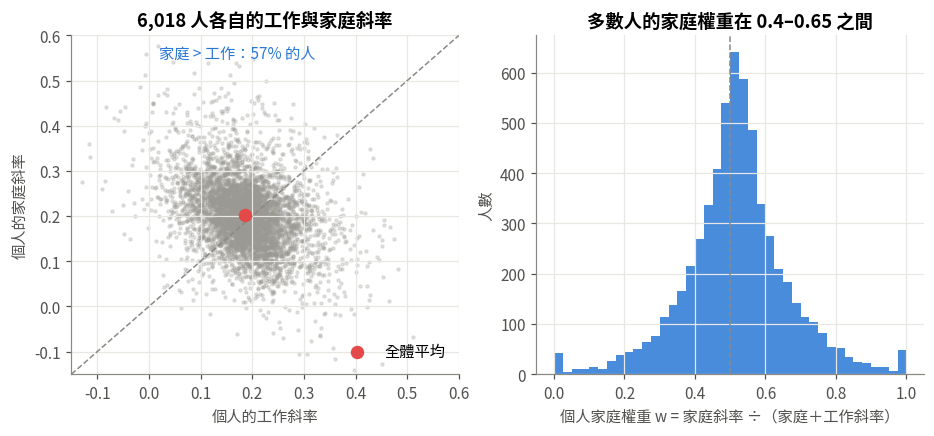

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.scatter(re.job_slope, re.fam_slope, s=4, alpha=0.25, color=PALETTE["grey"])
lim = [-0.15, 0.6]
ax.plot(lim, lim, color="#8a8984", lw=1, ls="--")
ax.scatter([bj], [bf], color=PALETTE["red"], s=60, zorder=3, label="全體平均")
ax.text(0.02, 0.55, f"家庭 > 工作：{(re.fam_slope > re.job_slope).mean()*100:.0f}% 的人", fontsize=10, color=C_FAMILY)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("個人的工作斜率"); ax.set_ylabel("個人的家庭斜率")
ax.set_title("6,018 人各自的工作與家庭斜率"); ax.legend(loc="lower right")
ax = axes[1]
ax.hist(re.w_family.clip(0, 1), bins=40, color=C_FAMILY, alpha=0.85)
ax.axvline(0.5, color="#8a8984", ls="--", lw=1)
ax.set_xlabel("個人家庭權重 w = 家庭斜率 ÷（家庭＋工作斜率）"); ax.set_ylabel("人數")
ax.set_title("多數人的家庭權重在 0.4–0.65 之間")
savefig(fig, "fig06_personal_weights")

## 3. 個人權重穩定嗎？前後兩段時期分開估計

把資料切成 2007–2014（前段）與 2016–2024（後段），兩段各自估一個隨機斜率模型，比較同一個人在兩段的 BLUP。
同時也用一個模型同時估兩段的個人斜率（每人 4 個隨機斜率），直接得到兩段個人斜率的潛在相關——這個相關已經扣除估計雜訊。

In [7]:
L["late"] = (L.year >= 2016).astype(int)
both = L.groupby("pid").late.agg(["min", "max", "size"])
cnt_e = L[L.late == 0].groupby("pid").size(); cnt_l = L[L.late == 1].groupby("pid").size()
keep = cnt_e[cnt_e >= 3].index.intersection(cnt_l[cnt_l >= 3].index)
LL = L[L.pid.isin(keep)].copy()
print("兩段都至少 3 波的人：", len(keep), "，觀測", len(LL))
blups = {}
for part, g in LL.groupby("late"):
    mm = smf.mixedlm(FIX, g, groups=g.pid, re_formula="~jobsat+famsat").fit(method="lbfgs", reml=True)
    b = pd.DataFrame(mm.random_effects).T; b.columns = ["u0", "u_job", "u_fam"]
    b["job"] = mm.fe_params["jobsat"] + b.u_job; b["fam"] = mm.fe_params["famsat"] + b.u_fam
    b["diff"] = b.fam - b.job
    blups[part] = b
stab = pd.DataFrame({k: [blups[0][k].corr(blups[1][k])] for k in ["job", "fam", "diff"]}, index=["前段 vs 後段 BLUP 相關"]).round(3)
stab

兩段都至少 3 波的人： 2442 ，觀測 23472


,job,fam,diff
前段 vs 後段 BLUP 相關,0.042,0.142,0.085


In [8]:
LL["job_e"] = LL.jobsat * (1 - LL.late); LL["job_l"] = LL.jobsat * LL.late
LL["fam_e"] = LL.famsat * (1 - LL.late); LL["fam_l"] = LL.famsat * LL.late
t0 = time.time()
m_two = smf.mixedlm("swb2 ~ job_e + job_l + fam_e + fam_l + health + age_c + I(age_c**2) + female + C(year)", LL,
                    groups=LL.pid, re_formula="~job_e + job_l + fam_e + fam_l").fit(method="lbfgs", reml=True)
print("耗時 %.0f 秒，收斂：" % (time.time() - t0), m_two.converged)
Cv = m_two.cov_re
sd = np.sqrt(np.diag(Cv))
corr = pd.DataFrame(Cv.values / np.outer(sd, sd), index=Cv.index, columns=Cv.columns).round(3)
corr

耗時 35 秒，收斂： True


,Group,job_e,job_l,fam_e,fam_l
Group,1.000,-0.108,0.005,-0.165,-0.125
job_e,-0.108,1.000,0.216,-0.113,0.148
job_l,0.005,0.216,1.000,-0.069,-0.511
fam_e,-0.165,-0.113,-0.069,1.000,0.131
fam_l,-0.125,0.148,-0.511,0.131,1.000


In [9]:
print("工作斜率：前段 vs 後段的潛在相關 =", corr.loc["job_e", "job_l"])
print("家庭斜率：前段 vs 後段的潛在相關 =", corr.loc["fam_e", "fam_l"])
# 「家庭−工作」差距的潛在相關
v = lambda a, b: Cv.loc[a, b]
var_d_e = v("fam_e", "fam_e") + v("job_e", "job_e") - 2 * v("fam_e", "job_e")
var_d_l = v("fam_l", "fam_l") + v("job_l", "job_l") - 2 * v("fam_l", "job_l")
cov_d = v("fam_e", "fam_l") - v("fam_e", "job_l") - v("job_e", "fam_l") + v("job_e", "job_l")
print("（家庭−工作）相對權重：前段 vs 後段的潛在相關 =", round(cov_d / np.sqrt(var_d_e * var_d_l), 3))

工作斜率：前段 vs 後段的潛在相關 = 0.216
家庭斜率：前段 vs 後段的潛在相關 = 0.131
（家庭−工作）相對權重：前段 vs 後段的潛在相關 = 0.098


## 4. 態度、人生階段能預測個人權重嗎？

以每個人的 BLUP（全期間模型）為結果變數，看各種「事前可以問到的」特質能解釋多少個人權重的差異（R²）。

In [10]:
person = re[["job_slope", "fam_slope", "w_family"]].copy()
person["fam_minus_job"] = person.fam_slope - person.job_slope
person = person.join(att[att.year == 2011].set_index("pid").mar6.rename("婚姻態度2011"))
person = person.join(att[att.year == 2020].set_index("pid").fo.rename("家庭導向FO2020"))
person = person.join(main[main.year == 2022].set_index("pid")[["fam_importance", "breadwinner"]].rename(columns={"fam_importance": "家庭重要性2022", "breadwinner": "傳統分工2022"}))
demo = L.groupby("pid").agg(女性=("female", "mean"), 出生年=("birth_year", "mean"), 有子女比例=("has_kids", "mean"),
                            有幼兒比例=("kid_under6", "mean"), 已婚比例=("married", "mean"), 教育年數=("edu_years", "mean"))
person = person.join(demo)
sets = {"婚姻態度2011": ["婚姻態度2011"], "家庭導向FO2020": ["家庭導向FO2020"], "家庭重要性2022": ["家庭重要性2022"],
        "傳統分工2022": ["傳統分工2022"], "人生階段（性別、出生年、子女、教育）": ["女性", "出生年", "有子女比例", "有幼兒比例", "教育年數"],
        "全部態度＋人生階段": ["婚姻態度2011", "家庭導向FO2020", "家庭重要性2022", "傳統分工2022", "女性", "出生年", "有子女比例", "有幼兒比例", "教育年數"]}
rows = []
for nm, cols in sets.items():
    q = person.dropna(subset=cols + ["fam_minus_job"])
    m = smf.ols("fam_minus_job ~ " + " + ".join(f"Q('{c}')" for c in cols), q).fit()
    cvr = cv_r2(q[cols].values, q.fam_minus_job.values)[0]
    rows.append(dict(預測變數=nm, N=len(q), R2=m.rsquared, CV_R2=cvr, 最顯著係數p=m.pvalues.drop("Intercept").min()))
pred = pd.DataFrame(rows).round(4)
pred

,預測變數,N,R2,CV_R2,最顯著係數p
0,婚姻態度2011,3862,0.0000,-0.0044,0.9445
1,家庭導向FO2020,4709,0.0019,0.0005,0.0031
2,家庭重要性2022,4724,0.0011,-0.0001,0.0201
3,傳統分工2022,4721,0.0004,-0.0013,0.1613
4,人生階段（性別、出生年、子女、教育）,5710,0.0091,0.0055,0.0003
5,全部態度＋人生階段,2548,0.0152,0.0028,0.0021


In [11]:
q = person.dropna(subset=sets["全部態度＋人生階段"] + ["fam_minus_job"])
mfull = smf.ols("fam_minus_job ~ " + " + ".join(f"Q('{c}')" for c in sets["全部態度＋人生階段"]), q).fit(cov_type="HC1")
coef_table(mfull)

,coef,se,p,ci_low,ci_high
Intercept,-0.3355,0.7761,0.6655,-1.8566,1.1855
Q('婚姻態度2011'),-0.0075,0.0053,0.1593,-0.0179,0.0029
Q('家庭導向FO2020'),0.0072,0.0065,0.2679,-0.0056,0.0200
Q('家庭重要性2022'),0.0042,0.0052,0.4148,-0.0059,0.0143
Q('傳統分工2022'),0.0005,0.0032,0.8706,-0.0057,0.0067
Q('女性'),0.0166,0.0054,0.0022,0.0060,0.0273
Q('出生年'),0.0002,0.0004,0.6610,-0.0006,0.0009
Q('有子女比例'),0.0189,0.0090,0.0370,0.0011,0.0366
Q('有幼兒比例'),0.0079,0.0162,0.6262,-0.0239,0.0397
Q('教育年數'),-0.0018,0.0010,0.0527,-0.0037,0.0000


## 5. 形式化檢定：在追蹤資料中，「重要性 × 滿意度」交互作用（跨層級交互作用）

In [12]:
LX = L.merge(main[main.year == 2022][["pid", "fam_importance"]], on="pid", how="left")
LX = LX.merge(att[att.year == 2020][["pid", "fo"]], on="pid", how="left")
for mod in ["fam_importance", "fo"]:
    g = LX.dropna(subset=[mod]).copy(); g["mz"] = z(g[mod])
    mm = smf.mixedlm(FIX + " + mz + jobsat:mz + famsat:mz", g, groups=g.pid, re_formula="~jobsat+famsat").fit(method="lbfgs", reml=True)
    print(f"{mod}: N 人 = {g.pid.nunique()}  工作×態度 = {mm.params['jobsat:mz']:.4f} (p={mm.pvalues['jobsat:mz']:.3f})  家庭×態度 = {mm.params['famsat:mz']:.4f} (p={mm.pvalues['famsat:mz']:.3f})")
    # 這個交互作用能解釋多少個人斜率變異？
    tau_f = mm.cov_re.loc["famsat", "famsat"]
    print(f"    家庭斜率的個人差異 SD = {np.sqrt(tau_f):.3f}；態度每差 1 SD 只改變 {abs(mm.params['famsat:mz']):.3f}")

fam_importance: N 人 = 4724  工作×態度 = -0.0129 (p=0.017)  家庭×態度 = 0.0120 (p=0.030)
    家庭斜率的個人差異 SD = 0.166；態度每差 1 SD 只改變 0.012


fo: N 人 = 4709  工作×態度 = -0.0195 (p=0.000)  家庭×態度 = 0.0060 (p=0.276)
    家庭斜率的個人差異 SD = 0.165；態度每差 1 SD 只改變 0.006


In [13]:
re.to_csv(DERIVED / "personal_slopes_blup.csv")
pred.to_csv(DERIVED / "personal_weight_prediction.csv", index=False)
pd.DataFrame({"項目": ["工作平均斜率", "家庭平均斜率", "工作個人SD", "家庭個人SD", "工作-家庭個人相關", "LR"],
              "值": [bj, bf, sd_j, sd_f, r_jf, lr]}).to_csv(DERIVED / "random_slope_summary.csv", index=False)